# PROJECT - Diabetic Retinopathy

## Project Problem - EDA and Data Preprocessing

##### Group No7




#### Name Of Students :



#### 1) Amit Gaurav - 251140001

#### 2) Geetanjali - 251140008

#### 3) Krishna Shanmughan - 251140011

#### 4) Manoj Kumar Parida - 251140013

#### 5) Nikhil Madankar - 251140014

# Importing Necessary Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import mode
from matplotlib.ticker import MaxNLocator
import numpy as np
import altair as alt

Loading and Checking The Data

In [ ]:
df = pd.read_csv('diabetes.csv')

In [ ]:
df.head()

In [ ]:
df.tail()

In [ ]:
df.shape

In [ ]:
df.columns

In [ ]:
df.info()

In [ ]:
df.describe()

In [ ]:
results = {}

# List of all attributes to process (excluding 'Outcome')
attributes = df.columns.tolist()
if 'Outcome' in attributes:
    attributes.remove('Outcome')

# Calculate statistics for each attribute
for col in attributes:
    col_mean = df[col].mean()

    col_median = df[col].median()
    try:
        col_mode = mode(df[col], keepdims=True).mode[0]
    except AttributeError:
        col_mode = df[col].mode().iloc[0]
    col_quartiles = df[col].quantile([0.25, 0.75]).to_dict()

    results[col] = {
        'Mean': col_mean,
        'Median': col_median,
        'Mode': col_mode,
        '25th Percentile (Q1)': col_quartiles[0.25],
        '75th Percentile (Q3)': col_quartiles[0.75]
    }

In [ ]:
stats_df = pd.DataFrame.from_dict(results, orient='index')
stats_df.index.name = 'Attribute'
print(stats_df.to_markdown(numalign="left", stralign="left", floatfmt=".3f"))

#

### Box Plot of Pregnancies

In [ ]:
color = sns.color_palette("viridis", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Pregnancies'], color=color)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.title('Box Plot of Pregnancies', fontsize=16)
plt.xlabel('Number of Pregnancies', fontsize=14)
plt.show()

### Box Plot of Glucose Concentration

In [ ]:
color = sns.color_palette("magma", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Glucose'], color=color)
plt.title('Box Plot of Glucose Concentration', fontsize=16)
plt.xlabel('Glucose (mg/dL)', fontsize=14)
plt.show()

# Box Plot of Diastolic Blood Pressure

In [ ]:
color = sns.color_palette("rocket", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['BloodPressure'], color=color)
plt.title('Box Plot of Diastolic Blood Pressure', fontsize=16)
plt.xlabel('Blood Pressure (mm Hg)', fontsize=14)
plt.show()

In [ ]:
color = sns.color_palette("mako", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['SkinThickness'], color=color)
plt.title('Box Plot of Triceps Skin Fold Thickness', fontsize=16)
plt.xlabel('Skin Thickness (mm)', fontsize=14)
plt.show()

# Box Plot of 2 Hour Serum Insulin

In [ ]:
color = sns.color_palette("flare", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Insulin'], color=color)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.title('Box Plot of 2-Hour Serum Insulin', fontsize=16)
plt.xlabel('Insulin (mu U/ml)', fontsize=14)
plt.yticks([])
plt.show()

In [ ]:
color = sns.color_palette("flare", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Insulin'], color=color)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.title('Box Plot of 2-Hour Serum Insulin', fontsize=16)
plt.xlabel('Insulin (mu U/ml)', fontsize=14)
plt.yticks([])
plt.show()

<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipython-input-51942427.py:6: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel('BMI ($\mathrm{kg/m}^2$)', fontsize=14)


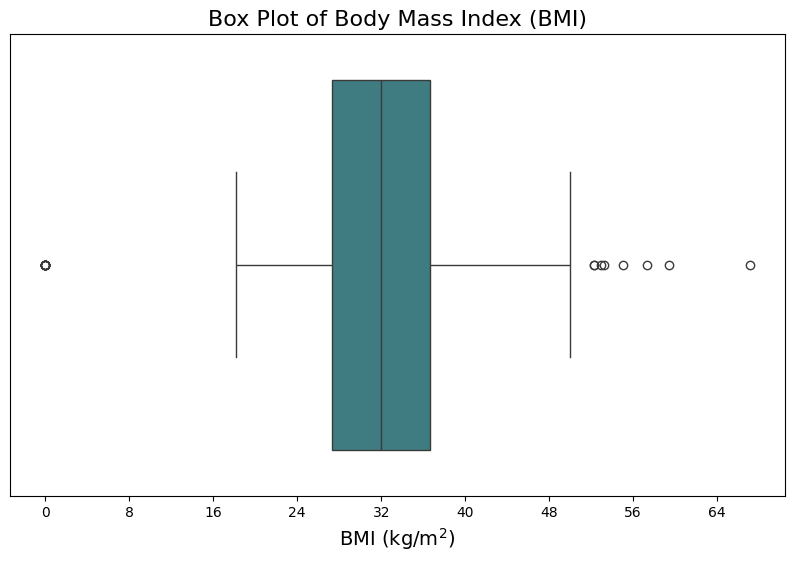

In [69]:
color = sns.color_palette("crest", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['BMI'], color=color)
plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=10))
plt.title('Box Plot of Body Mass Index (BMI)', fontsize=16)
plt.xlabel('BMI ($\mathrm{kg/m}^2$)', fontsize=14)
plt.yticks([])

plt.show()

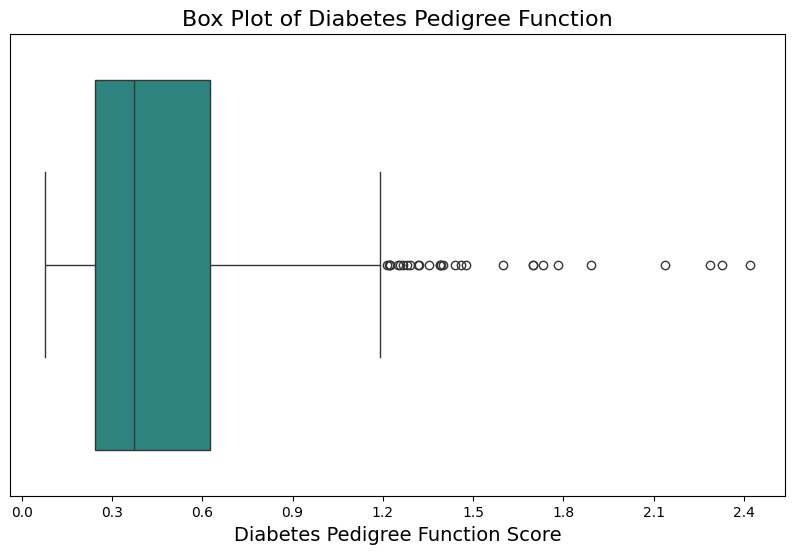

In [70]:
color = sns.color_palette("viridis", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['DiabetesPedigreeFunction'], color=color)
plt.gca().xaxis.set_major_locator(MaxNLocator(nbins=10))
plt.title('Box Plot of Diabetes Pedigree Function', fontsize=16)
plt.xlabel('Diabetes Pedigree Function Score', fontsize=14)
plt.yticks([])
plt.show()

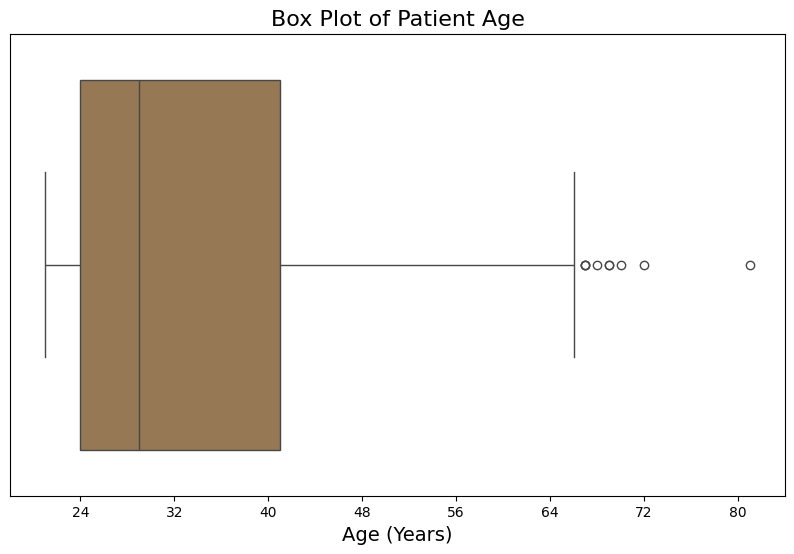

In [71]:
color = sns.color_palette("cubehelix", 1)[0]
plt.figure(figsize=(10, 6))
sns.boxplot(x=df['Age'], color=color)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.title('Box Plot of Patient Age', fontsize=16)
plt.xlabel('Age (Years)', fontsize=14)
plt.yticks([])
plt.show()

Correlation Matrix ( Heat Plot )   of Diabetes Dataset Attributes

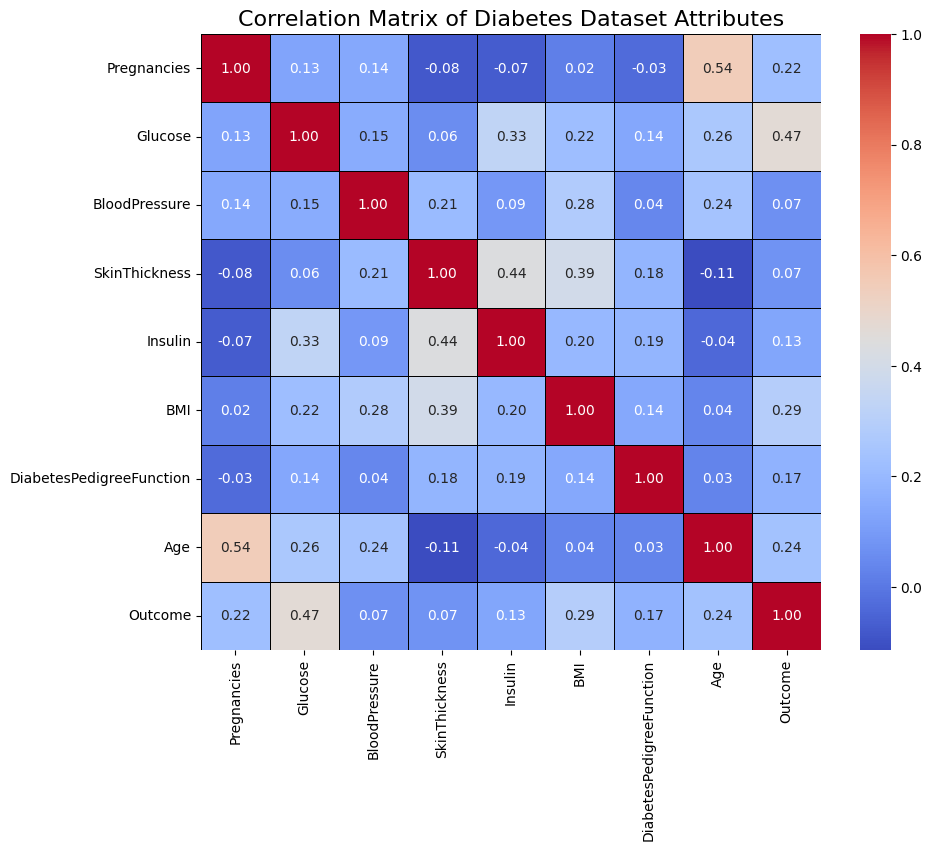


Correlation with Outcome (Diabetes Diagnosis):
Outcome                     1.000000
Glucose                     0.466581
BMI                         0.292695
Age                         0.238356
Pregnancies                 0.221898
DiabetesPedigreeFunction    0.173844
Insulin                     0.130548
SkinThickness               0.074752
BloodPressure               0.065068
Name: Outcome, dtype: float64


In [72]:
correlation_matrix = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap='coolwarm',
    cbar=True,
    linewidths=0.5,
    linecolor='black'
)
plt.title('Correlation Matrix of Diabetes Dataset Attributes', fontsize=16)
plt.show()
print("\nCorrelation with Outcome (Diabetes Diagnosis):")
print(correlation_matrix['Outcome'].sort_values(ascending=False))

Correlation Matrix ( Violine Plot )   of Diabetes Dataset Attributes

/tmp/ipython-input-3645986913.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipython-input-3645986913.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipython-input-3645986913.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipython-input-3645986913.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/tmp/ipython-input-3645986913.py:26: FutureWarni

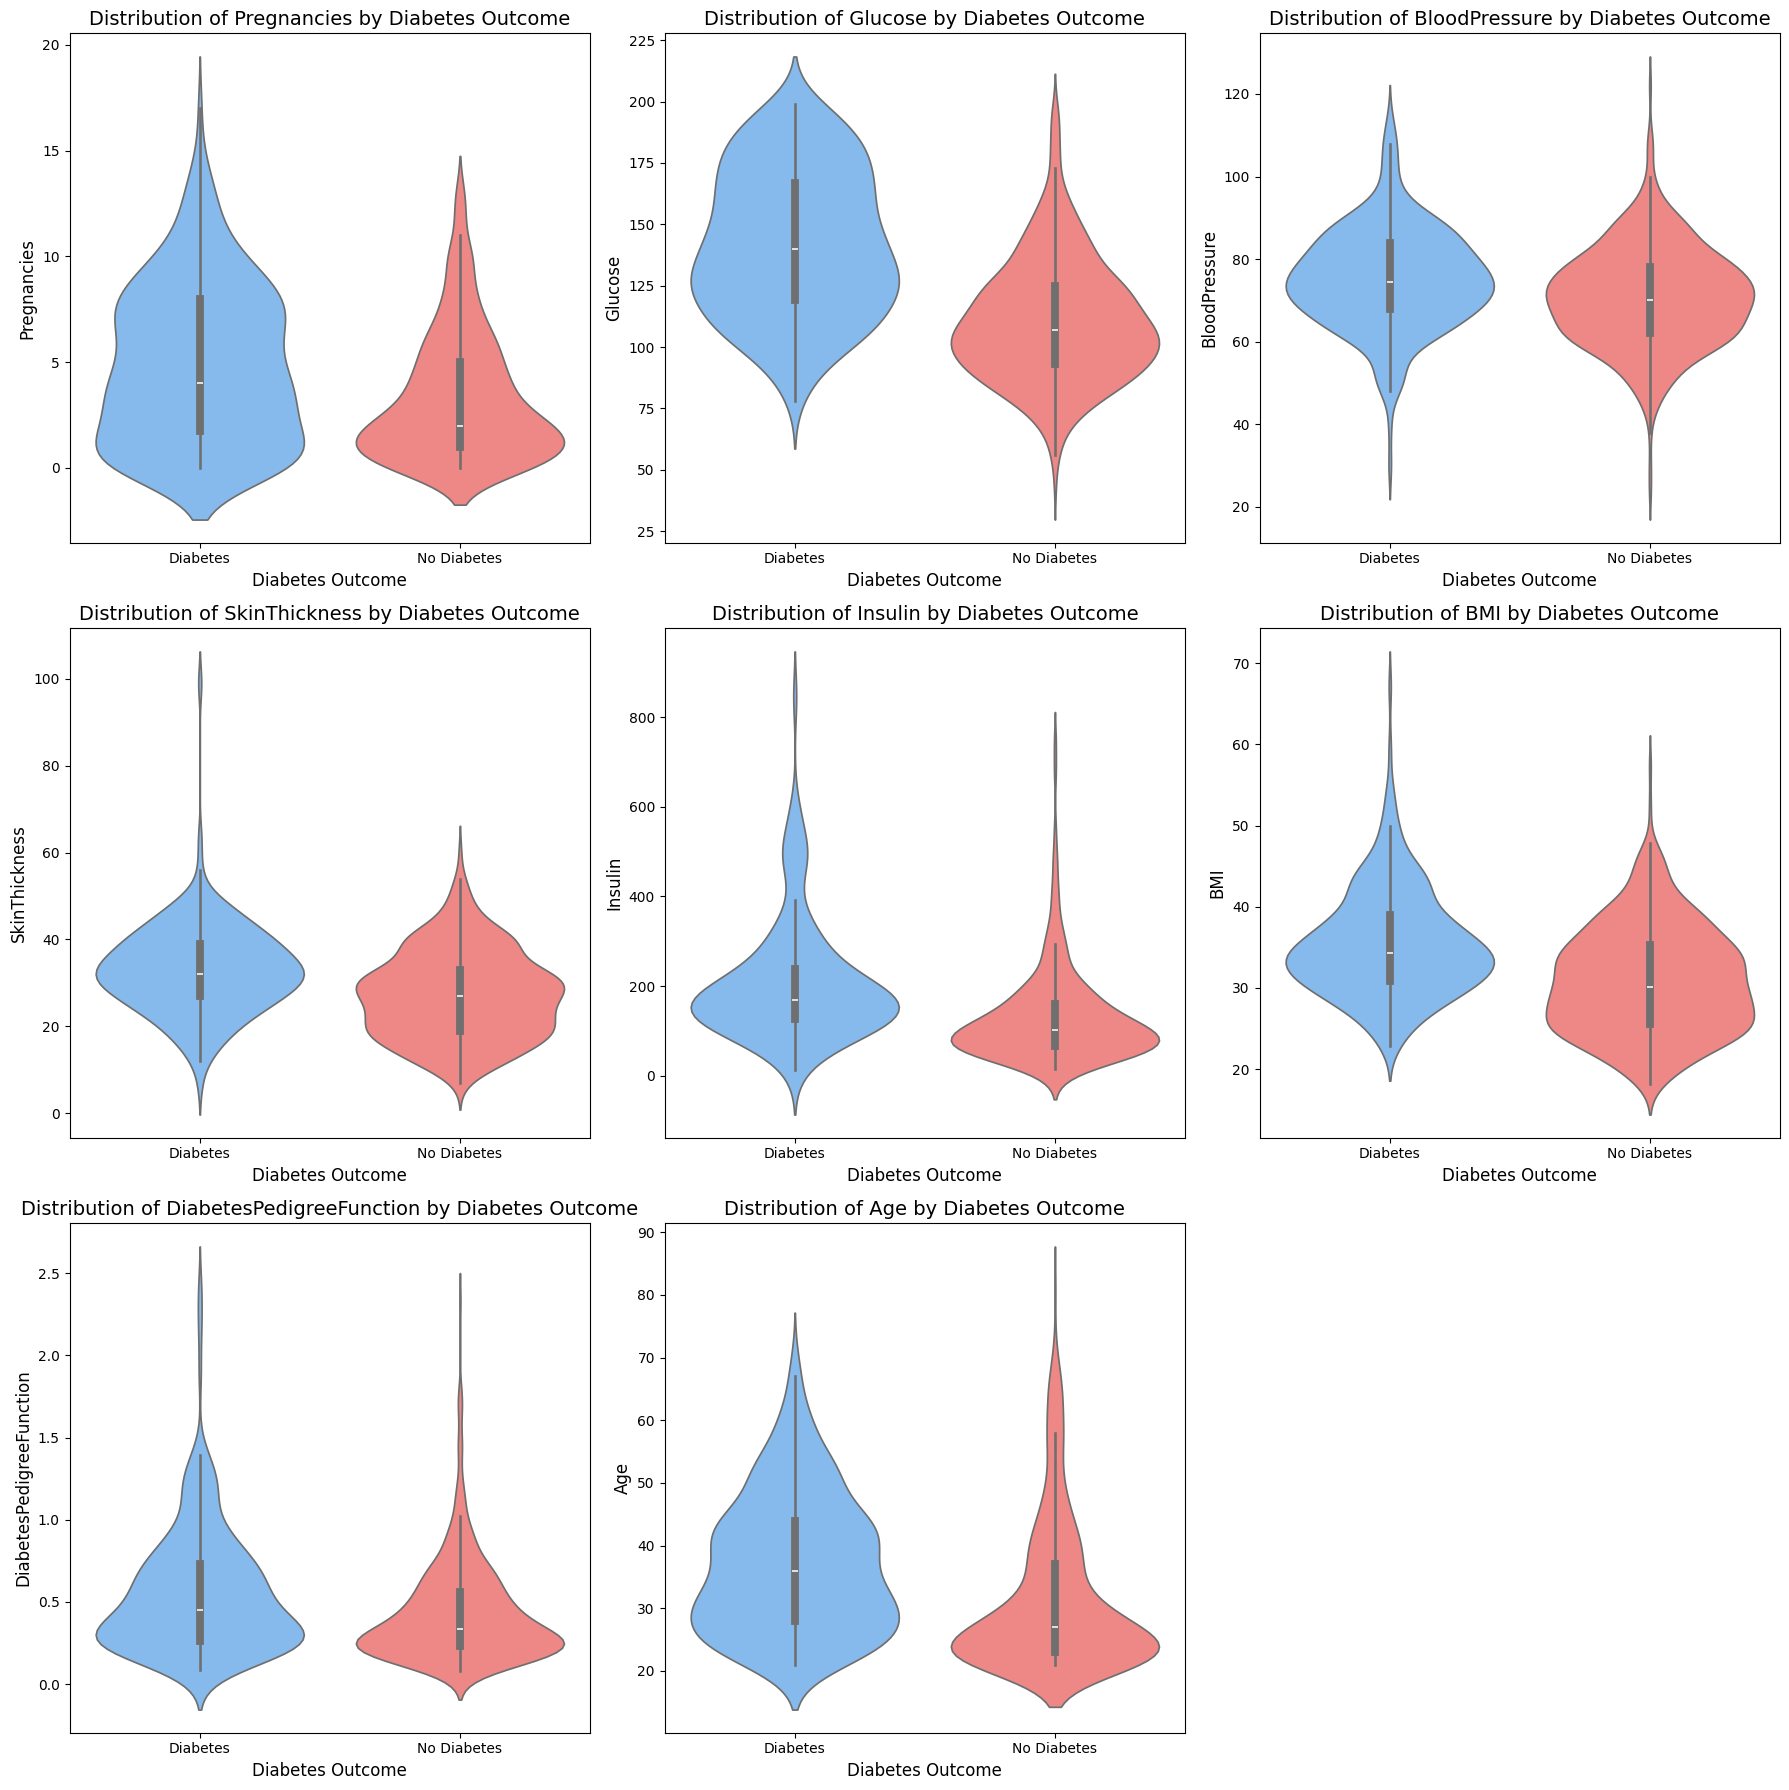

In [73]:
cols_to_clean = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

df_clean = df.copy()
df_clean[cols_to_clean] = df_clean[cols_to_clean].replace(0, np.nan)


predictor_attributes = [col for col in df_clean.columns if col != 'Outcome']

df_melted = df_clean.melt(id_vars='Outcome', value_vars=predictor_attributes,
                          var_name='Attribute', value_name='Value')


df_melted['Outcome_Label'] = df_melted['Outcome'].map({0: 'No Diabetes', 1: 'Diabetes'})

# Set up the subplot grid (3 rows, 3 columns for 8 attributes + 1 empty slot)
n_rows = 3
n_cols = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 18))
axes = axes.flatten()

for i, col in enumerate(predictor_attributes):
    # Filter the melted data for the current attribute
    data_to_plot = df_melted[df_melted['Attribute'] == col]

    # Create the violin plot
    sns.violinplot(
        x='Outcome_Label',
        y='Value',
        data=data_to_plot,
        ax=axes[i],
        palette=['#75bbfd', '#ff7875']
    )

    # Set titles and labels
    axes[i].set_title(f'Distribution of {col} by Diabetes Outcome', fontsize=14)
    axes[i].set_xlabel('Diabetes Outcome', fontsize=12)
    axes[i].set_ylabel(col, fontsize=12)

if len(predictor_attributes) < len(axes):
    fig.delaxes(axes[len(predictor_attributes)])

plt.tight_layout()


plt.show()

## Detect and treat outliers

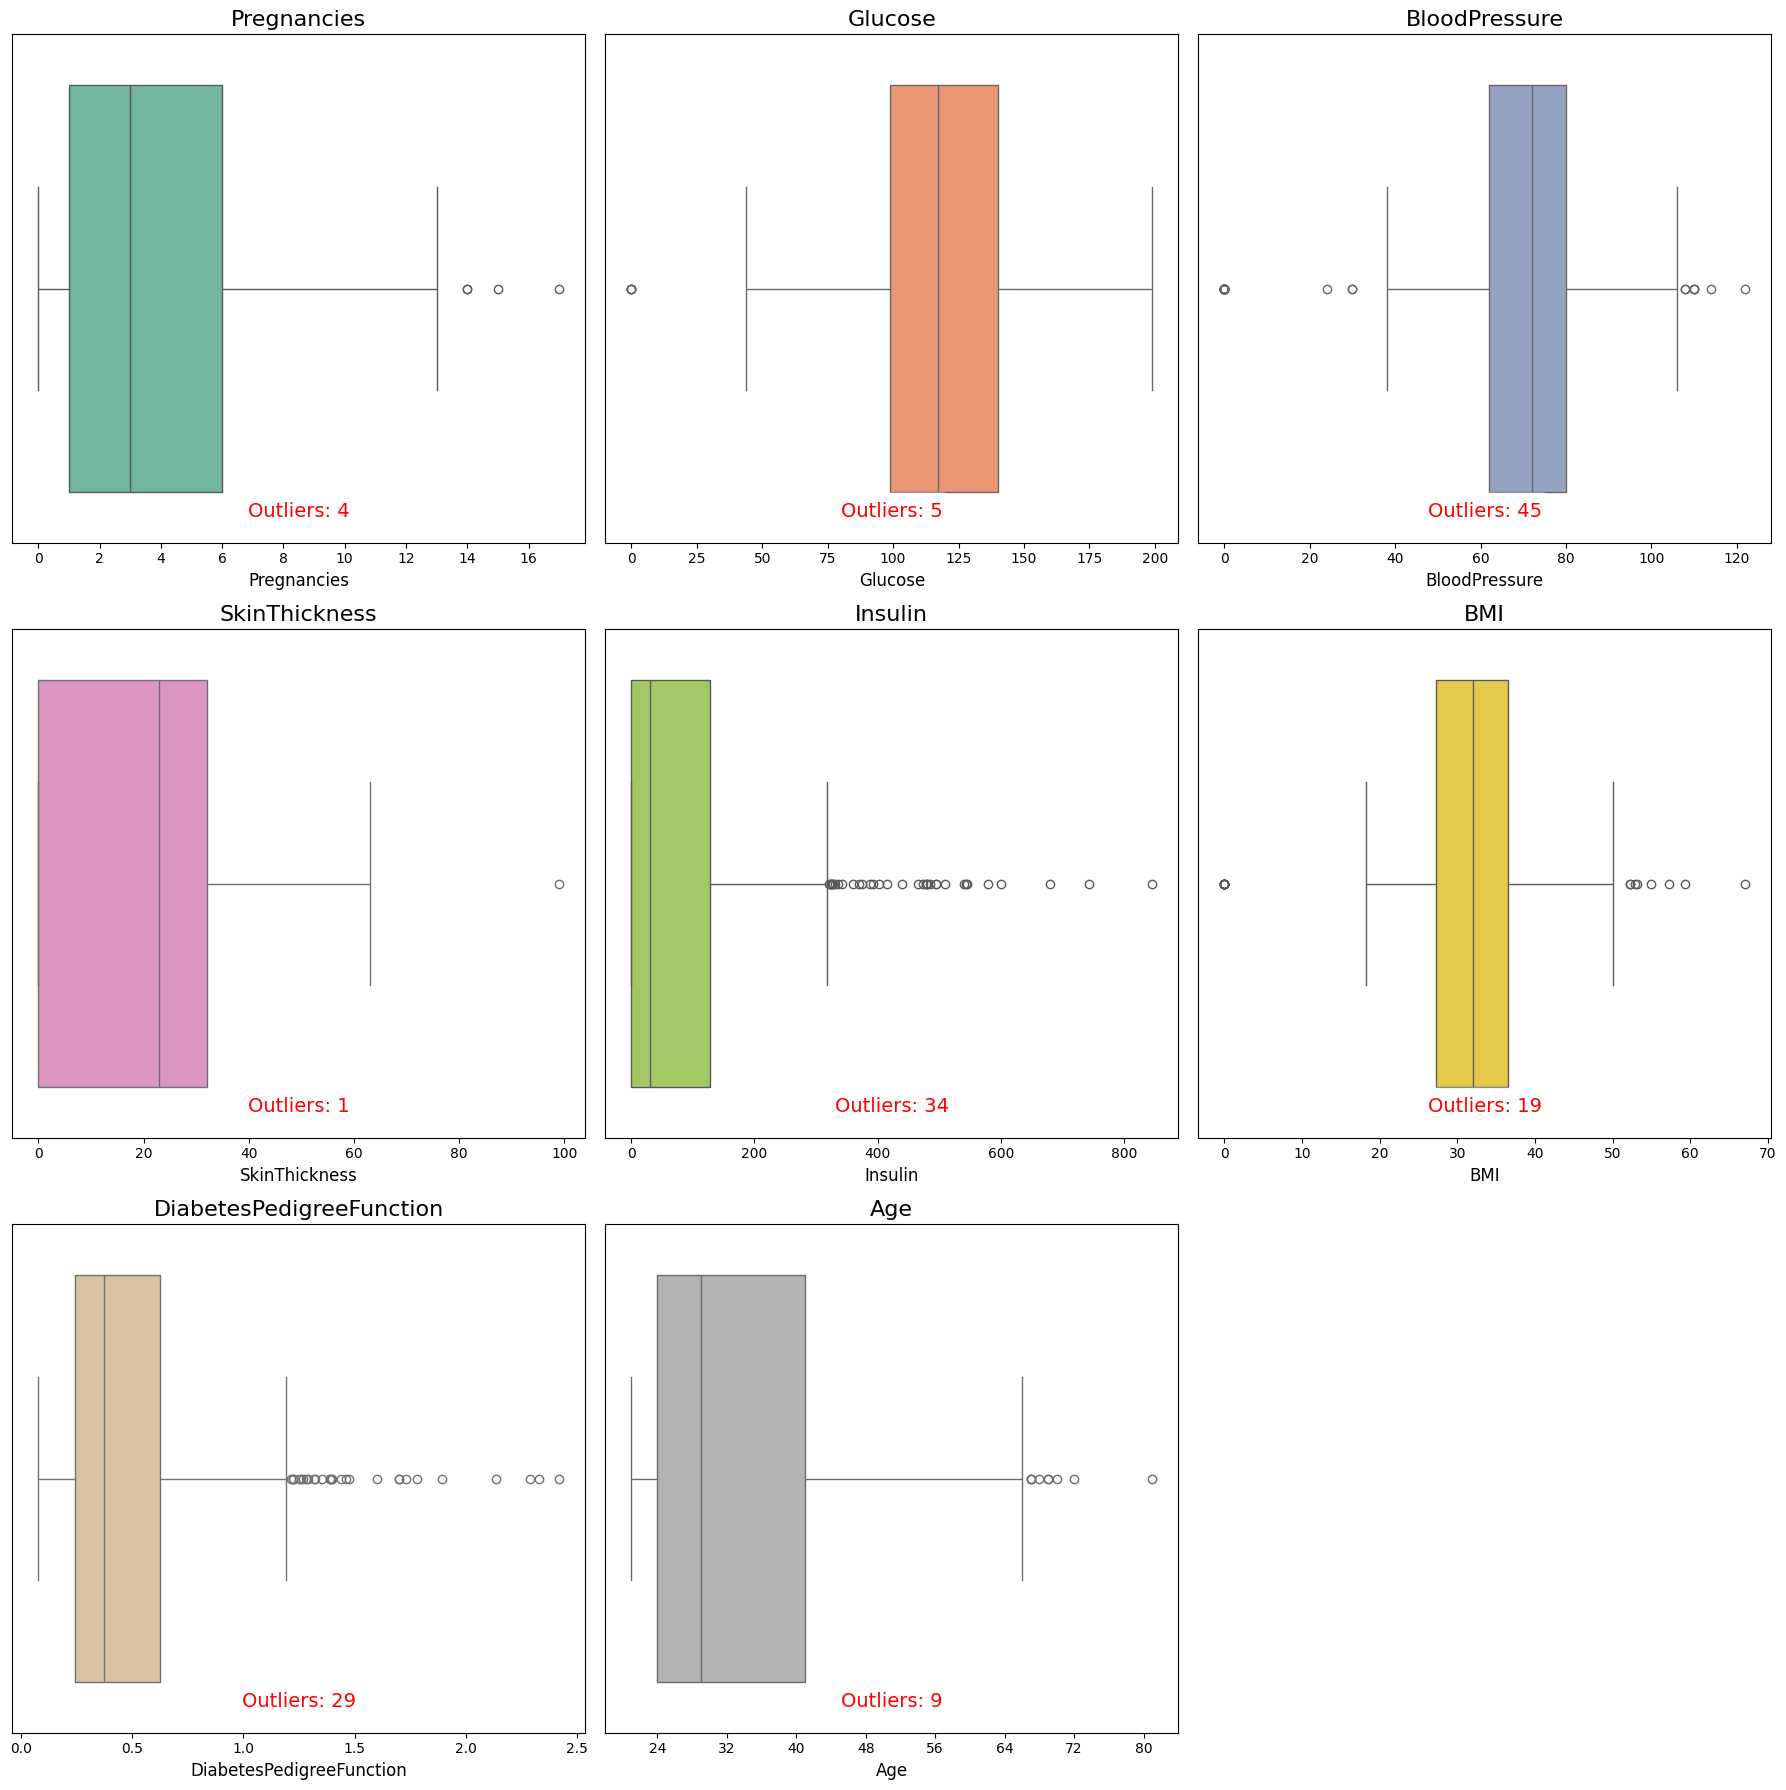

In [74]:
predictor_attributes = [col for col in df.columns if col != 'Outcome']

n_rows = 3
n_cols = 3
fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 18))
axes = axes.flatten()


for i, col in enumerate(predictor_attributes):

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    low_outliers = df[df[col] < lower_bound].shape[0]
    high_outliers = df[df[col] > upper_bound].shape[0]
    total_outliers = low_outliers + high_outliers

    sns.boxplot(x=df[col], ax=axes[i], color=sns.color_palette("Set2")[i % 8])


    axes[i].set_title(f'{col}', fontsize=16)
    axes[i].set_xlabel(col, fontsize=12)
    axes[i].set_yticks([])

    axes[i].text(
        0.5, 0.05,
        f'Outliers: {total_outliers}',
        transform=axes[i].transAxes,
        ha='center',
        fontsize=14,
        color='red',
        bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.5')
    )

    if col in ['Pregnancies', 'Age']:
        axes[i].xaxis.set_major_locator(MaxNLocator(integer=True))

if len(predictor_attributes) < len(axes):
    fig.delaxes(axes[len(predictor_attributes)])

plt.tight_layout()


plt.show()

### To deal with Outlier we need Domain knowladge

#### (1) Pregnancies

In [75]:
attribute = 'Pregnancies'

# 1. Calculate Quartiles and IQR
Q1 = df[attribute].quantile(0.25)
Q3 = df[attribute].quantile(0.75)
IQR = Q3 - Q1

# 2. Calculate Outlier Fences (Lower and Upper Bounds)
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Detect Outliers

outlier_mask = (df[attribute] < lower_bound) | (df[attribute] > upper_bound)
outliers_df = df[outlier_mask].copy()

# 4. Prepare the final table

outliers_table = outliers_df[[attribute, 'Outcome']]

# Rename columns for clarity in the output
outliers_table.columns = ['Outlier_Value (Pregnancies)', 'Outcome']

outliers_table = outliers_table.sort_values(by='Outlier_Value (Pregnancies)', ascending=False)

print(f"--- Outliers for {attribute} (IQR Bounds: {lower_bound:.2f} to {upper_bound:.2f}) ---")
print(f"Total Outliers: {outliers_table.shape[0]}")
print("\nOutlier Data Table:")


print(outliers_table.to_markdown(index=False, numalign="left", stralign="left", floatfmt=".0f"))


outcome_count = outliers_table['Outcome'].value_counts()
print("\nDistribution of Outcome in Outlier Data:")
print(outcome_count.to_markdown(numalign="left", stralign="left"))

--- Outliers for Pregnancies (IQR Bounds: -6.50 to 13.50) ---
Total Outliers: 4

Outlier Data Table:
| Outlier_Value (Pregnancies)   | Outcome   |
|:------------------------------|:----------|
| 17                            | 1         |
| 15                            | 1         |
| 14                            | 1         |
| 14                            | 1         |

Distribution of Outcome in Outlier Data:
| Outcome   | count   |
|:----------|:--------|
| 1         | 4       |


#### (2) Glucose

In [76]:
attribute = 'Glucose'

# 1. Calculate Quartiles and IQR
Q1 = df[attribute].quantile(0.25)
Q3 = df[attribute].quantile(0.75)
IQR = Q3 - Q1

# 2. Calculate Outlier Fences (Lower and Upper Bounds)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Detect Outliers

outlier_mask = (df[attribute] < lower_bound) | (df[attribute] > upper_bound)
outliers_df = df[outlier_mask].copy()

# 4. Prepare the final table

outliers_table = outliers_df[[attribute, 'Outcome']]


outliers_table.columns = ['Outlier_Value (Glucose)', 'Outcome']


outliers_table = outliers_table.sort_values(by='Outlier_Value (Glucose)', ascending=True)

print(f"--- Outliers for {attribute} (IQR Bounds: {lower_bound:.2f} to {upper_bound:.2f}) ---")
print(f"Total Outliers: {outliers_table.shape[0]}")
print("\nOutlier Data Table:")

print(outliers_table.to_markdown(index=False, numalign="left", stralign="left", floatfmt=".0f"))

# Also provide a count of how many times each Outcome appears in the outlier data
outcome_count = outliers_table['Outcome'].value_counts()
print("\nDistribution of Outcome in Outlier Data:")
print(outcome_count.to_markdown(numalign="left", stralign="left"))

--- Outliers for Glucose (IQR Bounds: 37.12 to 202.12) ---
Total Outliers: 5

Outlier Data Table:
| Outlier_Value (Glucose)   | Outcome   |
|:--------------------------|:----------|
| 0                         | 0         |
| 0                         | 0         |
| 0                         | 0         |
| 0                         | 1         |
| 0                         | 1         |

Distribution of Outcome in Outlier Data:
| Outcome   | count   |
|:----------|:--------|
| 0         | 3       |
| 1         | 2       |


#### (3) BloodPressur

In [77]:
attribute = 'BloodPressure'

# 1. Calculate Quartiles and IQR
Q1 = df[attribute].quantile(0.25)
Q3 = df[attribute].quantile(0.75)
IQR = Q3 - Q1

# 2. Calculate Outlier Fences (Lower and Upper Bounds)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Detect Outliers

outlier_mask = (df[attribute] < lower_bound) | (df[attribute] > upper_bound)
outliers_df = df[outlier_mask].copy()

# 4. Prepare the final table

outliers_table = outliers_df[[attribute, 'Outcome']]


outliers_table.columns = ['Outlier_Value (BloodPressure)', 'Outcome']

outliers_table = outliers_table.sort_values(by='Outlier_Value (BloodPressure)', ascending=True)


print(f"--- Outliers for {attribute} (IQR Bounds: {lower_bound:.0f} to {upper_bound:.0f}) ---")
print(f"Total Outliers: {outliers_table.shape[0]}")
print("\nOutlier Data Table:")


print(outliers_table.to_markdown(index=False, numalign="left", stralign="left", floatfmt=".0f"))

# Also provide a count of how many times each Outcome appears in the outlier data
outcome_count = outliers_table['Outcome'].value_counts()
print("\nDistribution of Outcome in Outlier Data:")
print(outcome_count.to_markdown(numalign="left", stralign="left"))

--- Outliers for BloodPressure (IQR Bounds: 35 to 107) ---
Total Outliers: 45

Outlier Data Table:
| Outlier_Value (BloodPressure)   | Outcome   |
|:--------------------------------|:----------|
| 0                               | 0         |
| 0                               | 1         |
| 0                               | 0         |
| 0                               | 0         |
| 0                               | 1         |
| 0                               | 0         |
| 0                               | 1         |
| 0                               | 0         |
| 0                               | 0         |
| 0                               | 1         |
| 0                               | 0         |
| 0                               | 0         |
| 0                               | 1         |
| 0                               | 1         |
| 0                               | 1         |
| 0                               | 1         |
| 0                               | 1

#### (4) Insulin

In [78]:
attribute = 'Insulin'

# 1. Calculate Quartiles and IQR
Q1 = df[attribute].quantile(0.25)
Q3 = df[attribute].quantile(0.75)
IQR = Q3 - Q1

# 2. Calculate Outlier Fences (Lower and Upper Bounds)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Detect Outliers

outlier_mask = (df[attribute] < lower_bound) | (df[attribute] > upper_bound)
outliers_df = df[outlier_mask].copy()

# 4. Prepare the final table
outliers_table = outliers_df[[attribute, 'Outcome']]

outliers_table.columns = ['Outlier_Value (Insulin)', 'Outcome']


outliers_table = outliers_table.sort_values(by='Outlier_Value (Insulin)', ascending=True)

# Display the results
print(f"--- Outliers for {attribute} (IQR Bounds: {lower_bound:.0f} to {upper_bound:.0f}) ---")
print(f"Total Outliers: {outliers_table.shape[0]}")
print("\nOutlier Data Table:")

print(outliers_table.to_markdown(index=False, numalign="left", stralign="left", floatfmt=".0f"))


outcome_count = outliers_table['Outcome'].value_counts()
print("\nDistribution of Outcome in Outlier Data:")
print(outcome_count.to_markdown(numalign="left", stralign="left"))

--- Outliers for Insulin (IQR Bounds: -191 to 318) ---
Total Outliers: 34

Outlier Data Table:
| Outlier_Value (Insulin)   | Outcome   |
|:--------------------------|:----------|
| 321                       | 1         |
| 325                       | 0         |
| 325                       | 1         |
| 325                       | 1         |
| 326                       | 0         |
| 328                       | 1         |
| 330                       | 0         |
| 335                       | 0         |
| 342                       | 0         |
| 360                       | 1         |
| 370                       | 1         |
| 375                       | 0         |
| 387                       | 0         |
| 392                       | 1         |
| 402                       | 0         |
| 415                       | 0         |
| 440                       | 0         |
| 465                       | 1         |
| 474                       | 1         |
| 478                  

#### (5) BMI

In [79]:
attribute = 'BMI'

# 1. Calculate Quartiles and IQR
Q1 = df[attribute].quantile(0.25)
Q3 = df[attribute].quantile(0.75)
IQR = Q3 - Q1

# 2. Calculate Outlier Fences (Lower and Upper Bounds)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Detect Outliers

outlier_mask = (df[attribute] < lower_bound) | (df[attribute] > upper_bound)
outliers_df = df[outlier_mask].copy()

# 4. Prepare the final table

outliers_table = outliers_df[[attribute, 'Outcome']]


outliers_table.columns = ['Outlier_Value (BMI)', 'Outcome']


outliers_table = outliers_table.sort_values(by='Outlier_Value (BMI)', ascending=True)

# Display the results
print(f"--- Outliers for {attribute} (IQR Bounds: {lower_bound:.2f} to {upper_bound:.2f}) ---")
print(f"Total Outliers: {outliers_table.shape[0]}")
print("\nOutlier Data Table:")

print(outliers_table.to_markdown(index=False, numalign="left", stralign="left", floatfmt=".1f"))

outcome_count = outliers_table['Outcome'].value_counts()
print("\nDistribution of Outcome in Outlier Data:")
print(outcome_count.to_markdown(numalign="left", stralign="left"))

--- Outliers for BMI (IQR Bounds: 13.35 to 50.55) ---
Total Outliers: 19

Outlier Data Table:
| Outlier_Value (BMI)   | Outcome   |
|:----------------------|:----------|
| 0.0                   | 1.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 0.0       |
| 0.0                   | 1.0       |
| 52.3                  | 1.0       |
| 52.3                  | 0.0       |
| 52.9                  | 1.0       |
| 53.2                  | 1.0       |
| 55.0                  | 1.0       |
| 57.3                  | 0.0       |
| 59.4                  | 1.0       |
| 67.1                  | 1.0       |

Distribution of Outcome in Outlier Data:
| Outcome   | count   |
|:----------|:--------|
| 0         | 11  

#### Outlier Treatment

##### Pregnancies

In [80]:
attribute = 'Pregnancies'

# 1. Calculate Quartiles and IQR
Q1 = df[attribute].quantile(0.25)
Q3 = df[attribute].quantile(0.75)
IQR = Q3 - Q1

# 2. Calculate Outlier Fences (Lower and Upper Bounds)

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# 3. Create a mask to identify OUTLIERS
outlier_mask = (df[attribute] < lower_bound) | (df[attribute] > upper_bound)

# 4. Filter the dataframe to KEEP only the NON-OUTLIER data
df_cleaned = df[~outlier_mask].copy()


rows_removed = df.shape[0] - df_cleaned.shape[0]
original_rows = df.shape[0]


new_filename = 'diabetes_pregnancies_outliers_removed.csv'
df_cleaned.to_csv(new_filename, index=False)

print(f"--- Outlier Removal for {attribute} ---")
print(f"Original number of rows: {original_rows}")
print(f"Number of outlier rows removed: {rows_removed}")
print(f"New number of rows: {df_cleaned.shape[0]}")
print(f"\nThe cleaned dataset has been saved to '{new_filename}'.")

--- Outlier Removal for Pregnancies ---
Original number of rows: 768
Number of outlier rows removed: 4
New number of rows: 764

The cleaned dataset has been saved to 'diabetes_pregnancies_outliers_removed.csv'.


##### Glucose

In [81]:
attribute_glucose = 'Glucose'


glucose_median = df_cleaned[df_cleaned[attribute_glucose] != 0][attribute_glucose].median()


df_cleaned[attribute_glucose] = df_cleaned[attribute_glucose].replace(0, glucose_median)

new_filename = 'diabetes_glucose_imputed.csv'
df_cleaned.to_csv(new_filename, index=False)

##### BloodPressure

In [82]:
attribute_bp = 'BloodPressure'

bp_median = df_cleaned[df_cleaned[attribute_bp] != 0][attribute_bp].median()

df_cleaned[attribute_bp] = df_cleaned[attribute_bp].replace(0, bp_median)

new_filename = 'diabetes_bp_imputed.csv'
df_cleaned.to_csv(new_filename, index=False)

##### Insulin

In [83]:
attribute_insulin = 'Insulin'

insulin_median = df[df[attribute_insulin] != 0][attribute_insulin].median()

df['Insulin_Imputed'] = df[attribute_insulin].replace(0, insulin_median)


df['Insulin_Log'] = np.log1p(df['Insulin_Imputed'])

df_cleaned = df.drop(columns=[attribute_insulin, 'Insulin_Imputed'])

new_filename = 'diabetes_insulin_original_treated.csv'
df_cleaned.to_csv(new_filename, index=False)

##### BMI

In [84]:
attribute_bmi = 'BMI'


bmi_median = df[df[attribute_bmi] != 0][attribute_bmi].median()


df['BMI_Imputed'] = df[attribute_bmi].replace(0, bmi_median)


Q1 = df[attribute_bmi].quantile(0.25)
Q3 = df[attribute_bmi].quantile(0.75)
IQR = Q3 - Q1
upper_bound_bmi = Q3 + 1.5 * IQR

df['BMI_Treated'] = np.where(
    df['BMI_Imputed'] > upper_bound_bmi,
    upper_bound_bmi,
    df['BMI_Imputed']
)


df_cleaned = df.drop(columns=[attribute_bmi, 'BMI_Imputed'])

new_filename = 'diabetes_bmi_original_treated.csv'
df_cleaned.to_csv(new_filename, index=False)

### Feature Engineering

#### -> Glucose_Insulin_Ratio = Glucose / Insulin

In [85]:
file_path = "diabetes_skinthickness_zeros_median.csv"

try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found.")
    # Exit if the file is not found
    exit()
epsilon = 1e-6
df['Glucose_Insulin_Ratio'] = df['Glucose'] / (df['Insulin'] + epsilon)


print("Successfully created the new feature 'Glucose_Insulin_Ratio'.\n")

print("DataFrame head with the new feature:\n")

print(df[['Glucose', 'Insulin', 'Glucose_Insulin_Ratio', 'Outcome']].head(10).to_markdown(index=False, numalign="left", stralign="left"))

print("\nSummary statistics for the new feature:\n")
print(df['Glucose_Insulin_Ratio'].describe().to_markdown(numalign="left", stralign="left"))

Successfully created the new feature 'Glucose_Insulin_Ratio'.

DataFrame head with the new feature:

| Glucose   | Insulin   | Glucose_Insulin_Ratio   | Outcome   |
|:----------|:----------|:------------------------|:----------|
| 148       | 125       | 1.184                   | 1         |
| 85        | 125       | 0.68                    | 0         |
| 183       | 125       | 1.464                   | 1         |
| 89        | 94        | 0.946809                | 0         |
| 137       | 2.225     | 61.573                  | 1         |
| 116       | 125       | 0.928                   | 0         |
| 78        | 88        | 0.886364                | 1         |
| 115       | 125       | 0.92                    | 0         |
| 197       | 2.735     | 72.0292                 | 1         |
| 125       | 125       | 1                       | 1         |

Summary statistics for the new feature:

|       | Glucose_Insulin_Ratio   |
|:------|:------------------------|
| count | 764    

#### Distribution Graph Before Normalization  

##### (1) Pregnancies

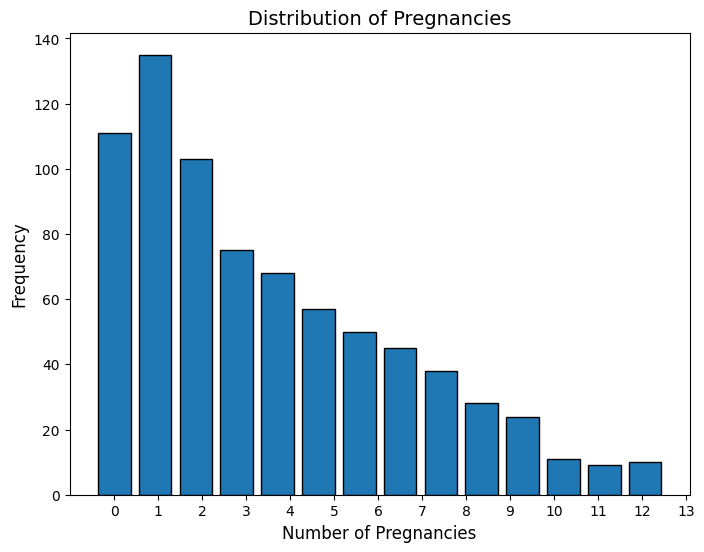

In [86]:
df = pd.read_csv("diabetes_skinthickness_zeros_median_1.csv")

# Create a figure and axis for the plot
fig, ax = plt.subplots(figsize=(8, 6))

# Plot the distribution of 'Pregnancies'.
# The number of bins is set to the maximum value + 1 to ensure each integer count
# (from 0 up to max) gets its own bin.
max_pregnancies = df['Pregnancies'].max()
bins = max_pregnancies + 1

df['Pregnancies'].hist(
    ax=ax,
    bins=bins,
    align='left',
    rwidth=0.8,
    edgecolor='black',
    grid=False
)

# Set the title and labels
ax.set_title('Distribution of Pregnancies', fontsize=14)
ax.set_xlabel('Number of Pregnancies', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)

# Set x-ticks to align with the integer values for clarity
ax.set_xticks(range(int(bins)))
ax.set_xticklabels(range(int(bins)))

# Display the plot
plt.show()

##### (2) Glucose

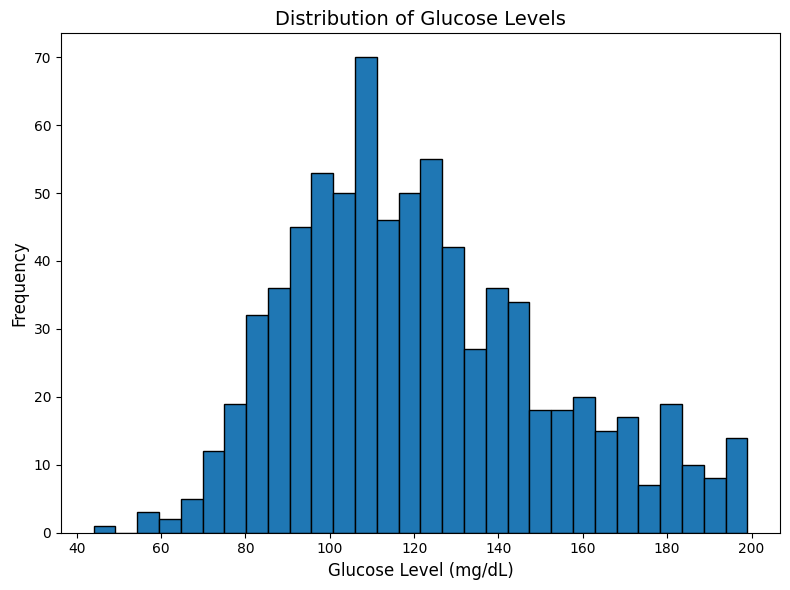

In [87]:
fig, ax = plt.subplots(figsize=(8, 6))


df['Glucose'].hist(
    ax=ax,
    bins=30,
    edgecolor='black',
    grid=False
)

ax.set_title('Distribution of Glucose Levels', fontsize=14)
ax.set_xlabel('Glucose Level (mg/dL)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)

plt.tight_layout()

##### (3) BloodPressure

Text(0, 0.5, 'Frequency')

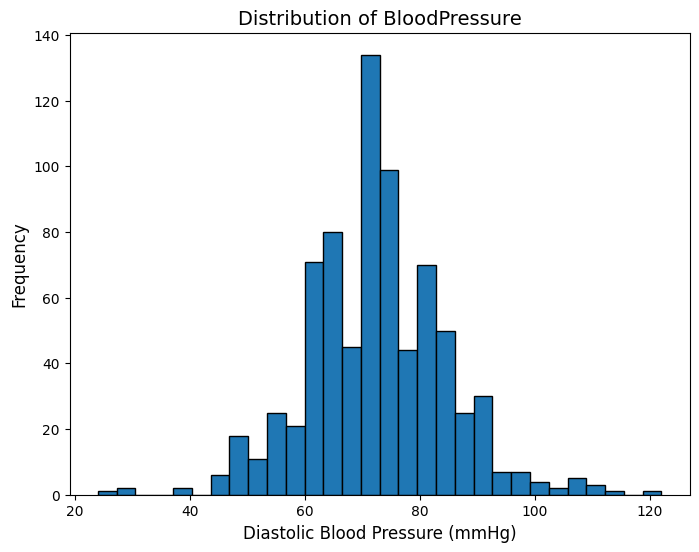

In [88]:
fig, ax = plt.subplots(figsize=(8, 6))


df['BloodPressure'].hist(
    ax=ax,
    bins=30,
    edgecolor='black',
    grid=False
)

ax.set_title('Distribution of BloodPressure', fontsize=14)
ax.set_xlabel('Diastolic Blood Pressure (mmHg)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)

##### (4) Distribution of SkinThickness

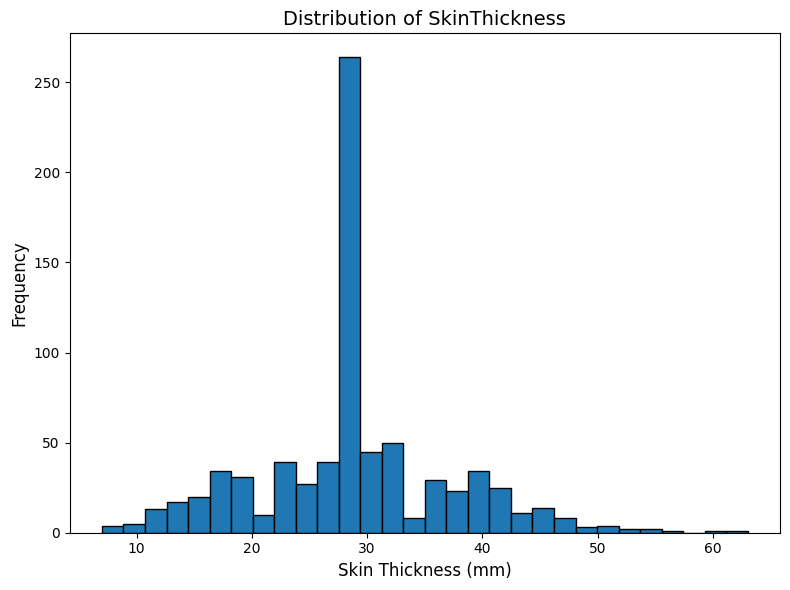

In [89]:
fig, ax = plt.subplots(figsize=(8, 6))


df['SkinThickness'].hist(
    ax=ax,
    bins=30,
    edgecolor='black',
    grid=False
)

ax.set_title('Distribution of SkinThickness', fontsize=14)
ax.set_xlabel('Skin Thickness (mm)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)


plt.tight_layout()


plt.show()

##### (5) Distribution of Insulin Levels

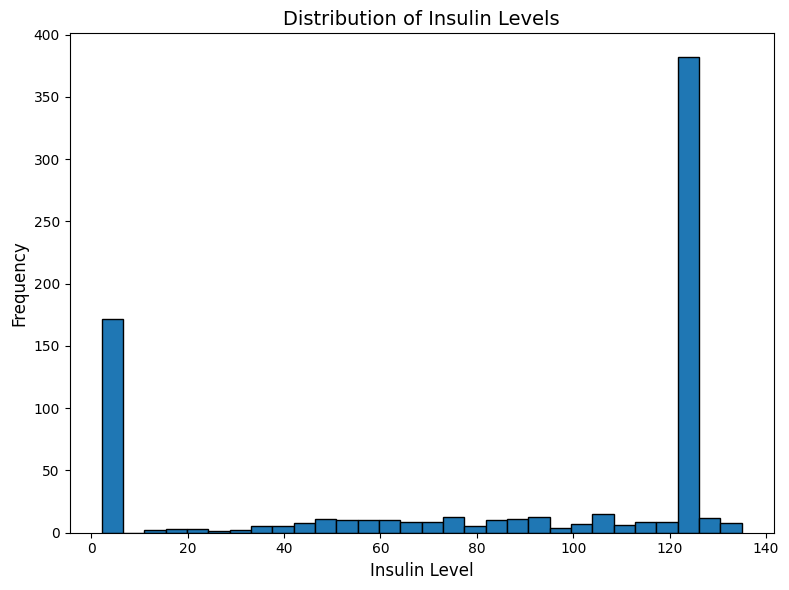

In [90]:
fig, ax = plt.subplots(figsize=(8, 6))

df['Insulin'].hist(
    ax=ax,
    bins=30,
    edgecolor='black',
    grid=False
)

# Set the title and labels
ax.set_title('Distribution of Insulin Levels', fontsize=14)
ax.set_xlabel('Insulin Level', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)


plt.tight_layout()

plt.show()

##### (5) BMI

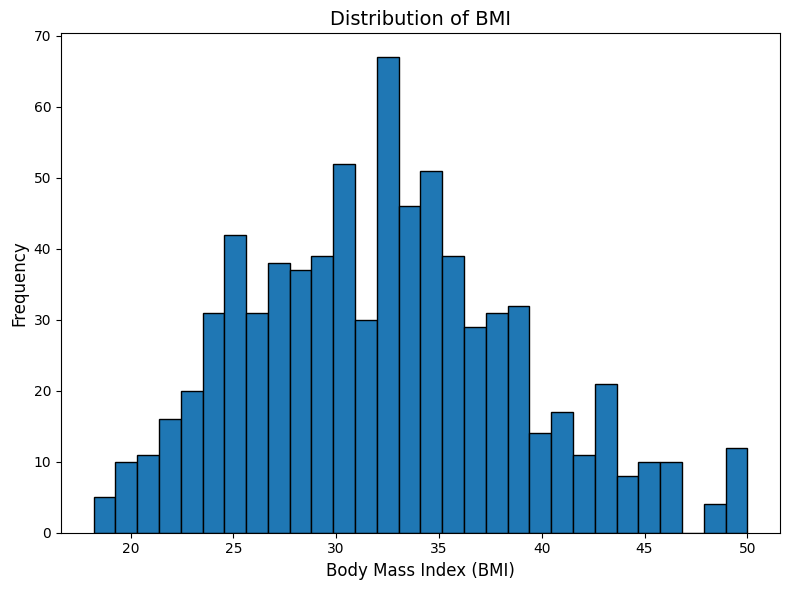

In [91]:
fig, ax = plt.subplots(figsize=(8, 6))


df['BMI'].hist(
    ax=ax,
    bins=30,
    edgecolor='black',
    grid=False
)

ax.set_title('Distribution of BMI', fontsize=14)
ax.set_xlabel('Body Mass Index (BMI)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)

# Ensure layout is tight
plt.tight_layout()

# Display the plot
plt.show()

##### (6) Diabete Pedigree Function

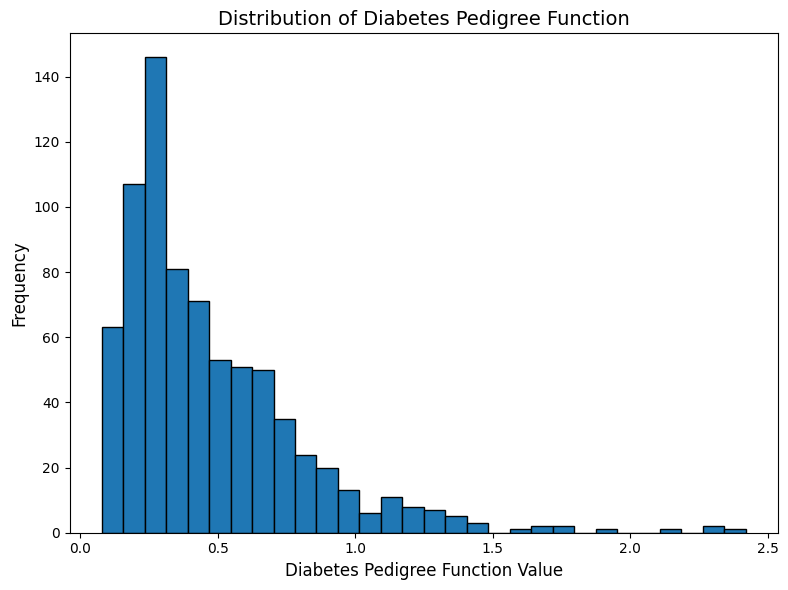

In [92]:
fig, ax = plt.subplots(figsize=(8, 6))


df['DiabetesPedigreeFunction'].hist(
    ax=ax,
    bins=30,
    edgecolor='black',
    grid=False
)

ax.set_title('Distribution of Diabetes Pedigree Function', fontsize=14)
ax.set_xlabel('Diabetes Pedigree Function Value', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)


plt.tight_layout()


plt.show()

##### (7) Age

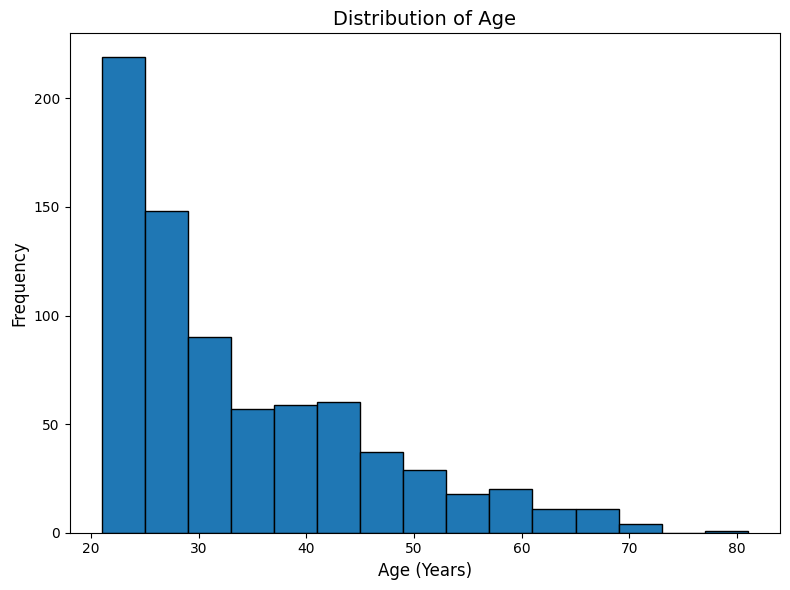

In [93]:
fig, ax = plt.subplots(figsize=(8, 6))


df['Age'].hist(
    ax=ax,
    bins=15,
    edgecolor='black',
    grid=False
)


ax.set_title('Distribution of Age', fontsize=14)
ax.set_xlabel('Age (Years)', fontsize=12)
ax.set_ylabel('Frequency', fontsize=12)

plt.tight_layout()

plt.show()

#### (8) Glucose_Insulin_Ratio

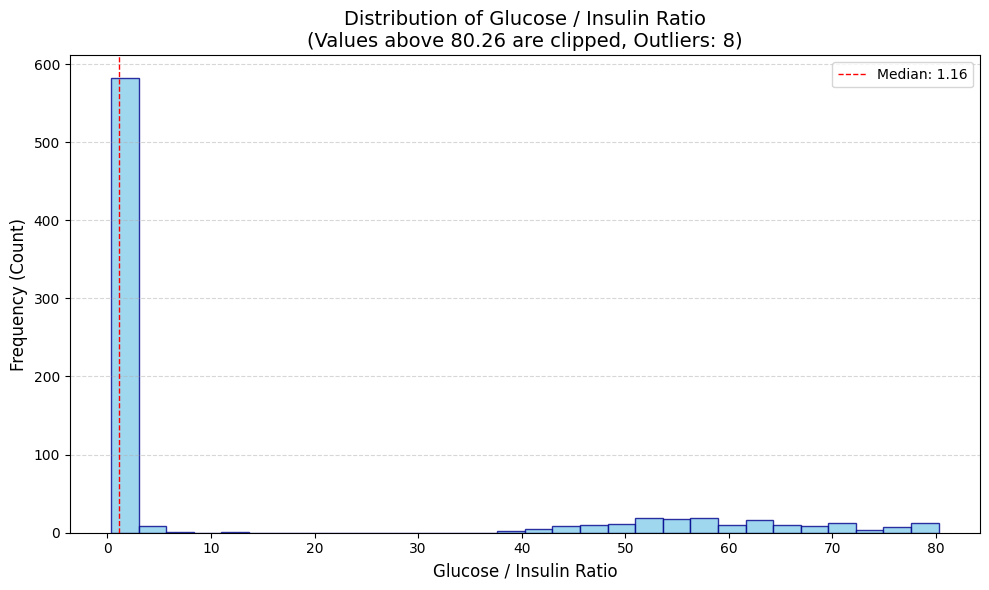

In [94]:
try:
    df = pd.read_csv(file_path)
except FileNotFoundError:
    print(f"Error: The file '{file_path}' was not found.")
    exit()
epsilon = 1e-6
df['Glucose_Insulin_Ratio'] = df['Glucose'] / (df['Insulin'] + epsilon)

upper_bound = df['Glucose_Insulin_Ratio'].quantile(0.99)
data_to_plot = df['Glucose_Insulin_Ratio'].clip(upper=upper_bound)

outlier_count = (df['Glucose_Insulin_Ratio'] > upper_bound).sum()


plt.figure(figsize=(10, 6))

plt.hist(data_to_plot, bins=30, color='skyblue', edgecolor='darkblue', alpha=0.8)

plt.title(
    f"Distribution of Glucose / Insulin Ratio\n(Values above {upper_bound:.2f} are clipped, Outliers: {outlier_count})",
    fontsize=14
)
plt.xlabel("Glucose / Insulin Ratio", fontsize=12)
plt.ylabel("Frequency (Count)", fontsize=12)
plt.grid(axis='y', alpha=0.5, linestyle='--')
plt.axvline(df['Glucose_Insulin_Ratio'].median(), color='red', linestyle='dashed', linewidth=1, label=f'Median: {df["Glucose_Insulin_Ratio"].median():.2f}')
plt.legend()
plt.tight_layout()

#### Normalization

#### (1) Pregnancies - min max normalization use minimum as 0 and maximum as 1

In [95]:
file_name = "diabetes_skinthickness_zeros_median.csv"
df_data = pd.read_csv(file_name)

min_val = df_data['Pregnancies'].min()
max_val = df_data['Pregnancies'].max()

df_data['Pregnancies_Normalized'] = (df_data['Pregnancies'] - min_val) / (max_val - min_val)
df_data['Pregnancies_Normalized'] = df_data['Pregnancies_Normalized'].round(3)

print(df_data.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50                  1.184        1   
1                     0.351   31                  0.680        0   
2                     0.672   32                  1.464        1   
3                     0.167   21                  0.947        0   
4                     2.288   33                 61.564        1   

   Pregnancies_Normalized  
0                   0.462  
1                   0.077  
2                   0.615  
3                   0.077  
4                 

#### (2) Glucose - z score normalization

In [96]:
mean_val = df['Glucose'].mean()
std_dev = df['Glucose'].std()
df['Glucose_Normalized_ZScore'] = (df['Glucose'] - mean_val) / std_dev

df['Glucose_Normalized_ZScore'] = df['Glucose_Normalized_ZScore'].round(3)

print(df.head())
output_file_name = "diabetes_normalized_data.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  
0                      0.870  
1                     -1.202  
2                      2.021  
3                     -1.070  
4  

#### (3) BloodPressure - z score normalization

In [97]:
mean_val_bp = df['BloodPressure'].mean()
std_dev_bp = df['BloodPressure'].std()

df['BloodPressure_Normalized_ZScore'] = (df['BloodPressure'] - mean_val_bp) / std_dev_bp

df['BloodPressure_Normalized_ZScore'] = df['BloodPressure_Normalized_ZScore'].round(3)

print(df.head())

output_file_name = "diabetes_normalized_data.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  BloodPressure_Normalized_ZScore  
0                      0.870                           -0.033  
1                     -1.202  

#### (4) SkinThickness - z score normalization

In [98]:
mean_val_st = df['SkinThickness'].mean()
std_dev_st = df['SkinThickness'].std()

df['SkinThickness_Normalized_ZScore'] = (df['SkinThickness'] - mean_val_st) / std_dev_st

df['SkinThickness_Normalized_ZScore'] = df['SkinThickness_Normalized_ZScore'].round(3)

print(df.head())

output_file_name = "diabetes_normalized_data.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  BloodPressure_Normalized_ZScore  \
0                      0.870                           -0.033   
1                     -1.202

#### (5) Insulin - Robust normalization

In [99]:
median_val_ins = df['Insulin'].median()

q1_ins = df['Insulin'].quantile(0.25)
q3_ins = df['Insulin'].quantile(0.75)
iqr_ins = q3_ins - q1_ins

if iqr_ins == 0:

    df['Insulin_Normalized_Robust'] = 0.0
else:
    df['Insulin_Normalized_Robust'] = (df['Insulin'] - median_val_ins) / iqr_ins

df['Insulin_Normalized_Robust'] = df['Insulin_Normalized_Robust'].round(3)

print(df.head())
output_file_name = "diabetes_normalized_data_final.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  BloodPressure_Normalized_ZScore  \
0                      0.870                           -0.033   
1                     -1.202

#### (6) BMI - z score normalization

In [100]:
mean_val_bmi = df['BMI'].mean()
std_dev_bmi = df['BMI'].std()

df['BMI_Normalized_ZScore'] = (df['BMI'] - mean_val_bmi) / std_dev_bmi

df['BMI_Normalized_ZScore'] = df['BMI_Normalized_ZScore'].round(3)

print(df.head())

output_file_name = "diabetes_normalized_data_final.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  BloodPressure_Normalized_ZScore  \
0                      0.870                           -0.033   
1                     -1.202

#### (7) Diabetes_Pedigree_Function - Robust normalization

In [101]:
median_val_dpf = df['DiabetesPedigreeFunction'].median()

q1_dpf = df['DiabetesPedigreeFunction'].quantile(0.25)
q3_dpf = df['DiabetesPedigreeFunction'].quantile(0.75)
iqr_dpf = q3_dpf - q1_dpf

if iqr_dpf == 0:

    df['DPF_Normalized_Robust'] = 0.0
else:
    df['DPF_Normalized_Robust'] = (df['DiabetesPedigreeFunction'] - median_val_dpf) / iqr_dpf


df['DPF_Normalized_Robust'] = df['DPF_Normalized_Robust'].round(3)

print(df.head())

output_file_name = "diabetes_normalized_data_final.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  BloodPressure_Normalized_ZScore  \
0                      0.870                           -0.033   
1                     -1.202

#### (8) Age - Robust normalization

In [102]:
median_val_age = df['Age'].median()

q1_age = df['Age'].quantile(0.25)
q3_age = df['Age'].quantile(0.75)
iqr_age = q3_age - q1_age

if iqr_age == 0:

    df['Age_Normalized_Robust'] = 0.0
else:
    df['Age_Normalized_Robust'] = (df['Age'] - median_val_age) / iqr_age

df['Age_Normalized_Robust'] = df['Age_Normalized_Robust'].round(3)

print(df.head())

output_file_name = "diabetes_normalized_data_final.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  BloodPressure_Normalized_ZScore  \
0                      0.870                           -0.033   
1                     -1.202

#### (9) Glucose_Insulin_Ratio - Robust Scaler

In [103]:
median_val_gir = df['Glucose_Insulin_Ratio'].median()

q1_gir = df['Glucose_Insulin_Ratio'].quantile(0.25)
q3_gir = df['Glucose_Insulin_Ratio'].quantile(0.75)
iqr_gir = q3_gir - q1_gir

if iqr_gir == 0:

    df['GIR_Normalized_Robust'] = 0.0
else:
    df['GIR_Normalized_Robust'] = (df['Glucose_Insulin_Ratio'] - median_val_gir) / iqr_gir


df['GIR_Normalized_Robust'] = df['GIR_Normalized_Robust'].round(3)

print(df.head())

output_file_name = "diabetes_normalized_data_final.csv"
df.to_csv(output_file_name, index=False)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35  125.000  33.6   
1            1       85             66             29  125.000  26.6   
2            8      183             64             29  125.000  23.3   
3            1       89             66             23   94.000  28.1   
4            0      137             40             35    2.225  43.1   

   DiabetesPedigreeFunction  Age  Glucose_Insulin_Ratio  Outcome  \
0                     0.627   50               1.184000        1   
1                     0.351   31               0.680000        0   
2                     0.672   32               1.464000        1   
3                     0.167   21               0.946809        0   
4                     2.288   33              61.573006        1   

   Glucose_Normalized_ZScore  BloodPressure_Normalized_ZScore  \
0                      0.870                           -0.033   
1                     -1.202

### Distribution Graph after Normalization

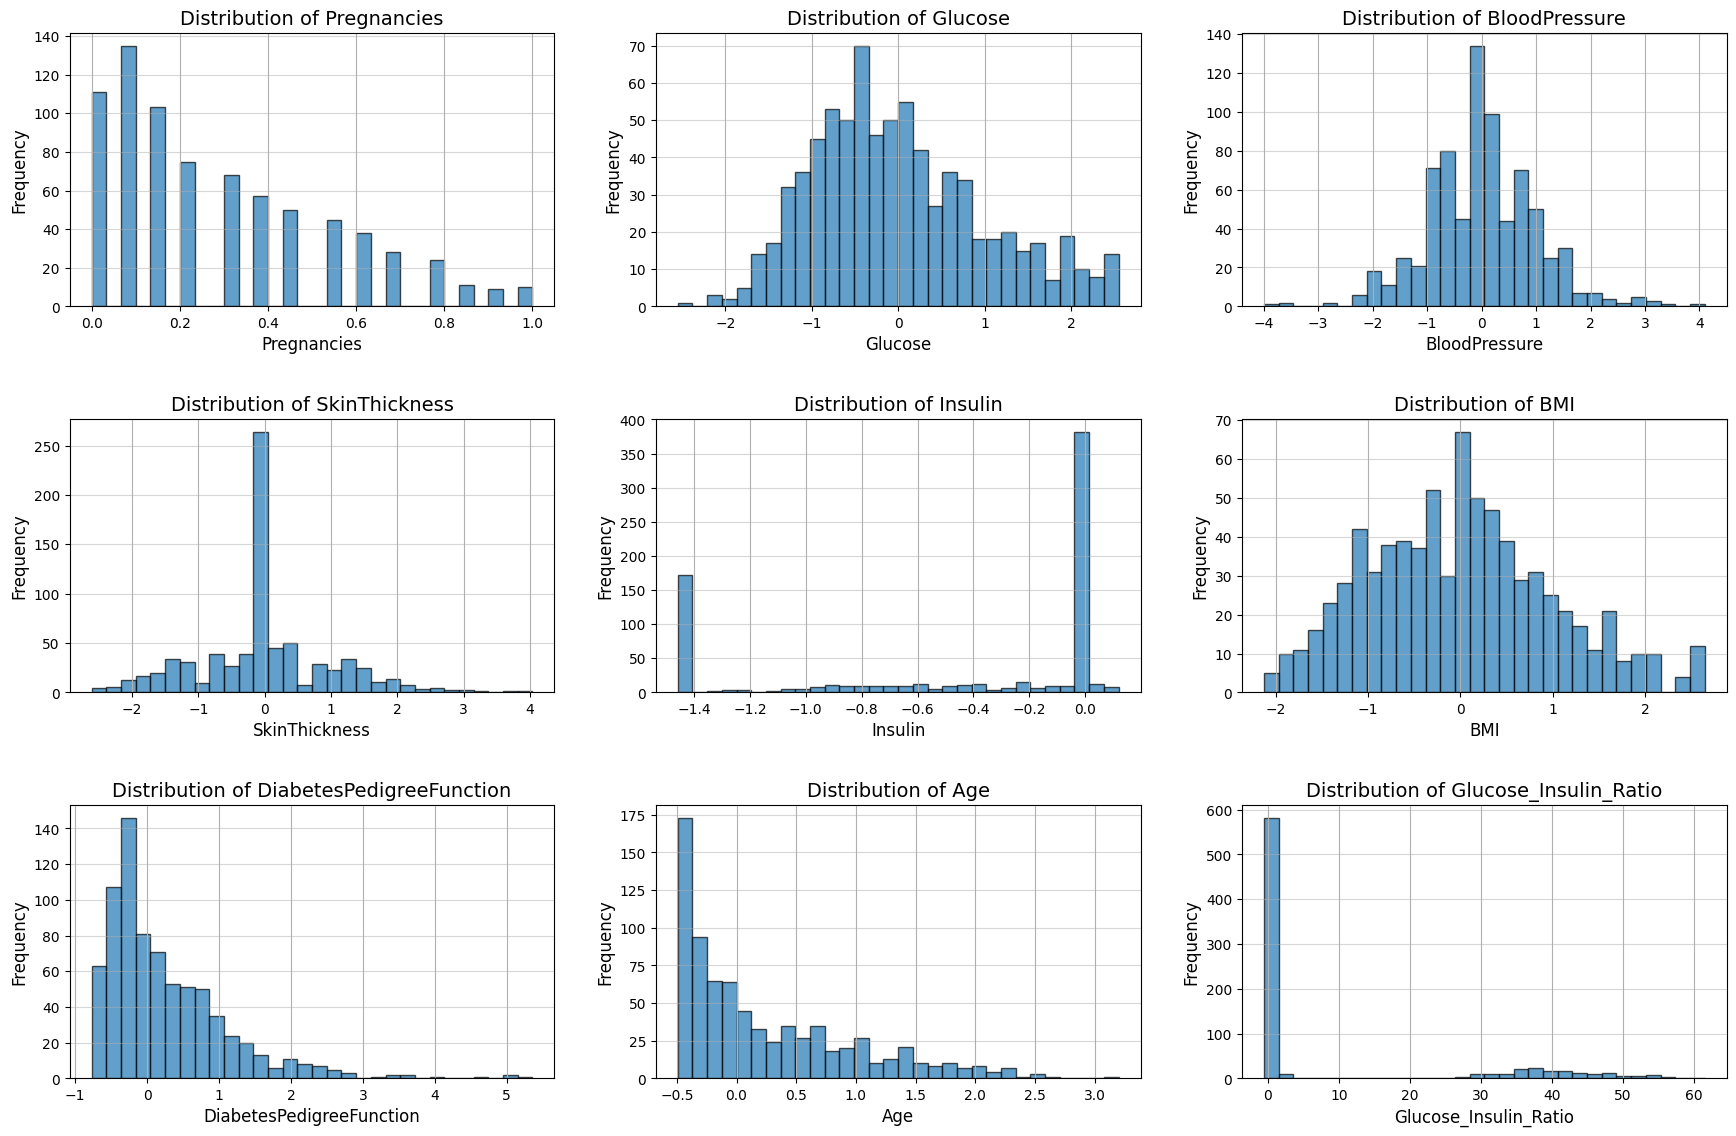

In [104]:
file_name = "diabetes_normalized_rounded.xls"
df = pd.read_csv(file_name)
columns_to_plot = [col for col in df.columns if col != 'Outcome']
n_cols = 3
n_rows = int(np.ceil(len(columns_to_plot) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(columns_to_plot):
    ax = axes[i]
    df[col].hist(bins=30, ax=ax, edgecolor='black', alpha=0.7)
    ax.set_title(f'Distribution of {col}', fontsize=14)
    ax.set_xlabel(col, fontsize=12)
    ax.set_ylabel('Frequency', fontsize=12)
    ax.grid(axis='y', alpha=0.5)

for j in range(len(columns_to_plot), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout(pad=3.0)
plot_filename = "attributes_distribution_plot.png"
plt.savefig(plot_filename)

In [105]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import LeaveOneOut
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
df = pd.read_csv('Group_7_Data_Mining_Project_Diabetic_Retinopathy_Processed_data_96325f16-8a87-4a9e-9c86-339c3f12963a.csv')

In [106]:
# Display basic dataset info
print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
print(df.head())
print("\nDataset Info:")
print(df.info())
print("\nTarget variable distribution:")
print(df['Outcome'].value_counts())

Dataset Shape: (764, 10)

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin    BMI  \
0        0.462    0.871         -0.033          0.713    0.000  0.185   
1        0.077   -1.203         -0.528          0.001    0.000 -0.865   
2        0.615    2.023         -0.693          0.001    0.000 -1.361   
3        0.077   -1.071         -0.528         -0.711   -0.368 -0.640   
4        0.000    0.509         -2.675          0.713   -1.457  1.611   

   DiabetesPedigreeFunction    Age  Glucose_Insulin_Ratio  Outcome  
0                     0.666  1.292                  0.015        1  
1                    -0.056  0.123                 -0.333        0  
2                     0.784  0.185                  0.208        1  
3                    -0.538 -0.492                 -0.148        0  
4                     5.011  0.246                 41.685        1  

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 764 entries, 0 to 763
Data columns (total 

In [107]:
# Prepare features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# Initialize models
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100),
    'Neural Network': MLPClassifier(random_state=42, max_iter=1000),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss')
}

# Initialize Leave-One-Out cross-validator
loo = LeaveOneOut()

# Store results
results = {}
roc_data = {}

In [ ]:
# Function to calculate specificity
def specificity_score(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    return tn / (tn + fp) if (tn + fp) > 0 else 0

# Perform Leave-One-Out Cross Validation
print("Performing Leave-One-Out Cross Validation...")
print("=" * 60)

for model_name, model in models.items():
    print(f"\nTraining {model_name}...")

    # Store predictions and probabilities
    y_true_all = []
    y_pred_all = []
    y_prob_all = []

    # Scale features for Neural Network
    if model_name == 'Neural Network':
        scaler = StandardScaler()
        X_scaled = scaler.fit_transform(X)
        # Convert scaled numpy array back to DataFrame to maintain original index
        X_scaled = pd.DataFrame(X_scaled, index=X.index, columns=X.columns)
    else:
        X_scaled = X

    # Leave-One-Out Cross Validation
    for train_index, test_index in loo.split(X):
        X_train, X_test = X_scaled.iloc[train_index], X_scaled.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        # Train model
        model.fit(X_train, y_train)

        # Predict
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        # Store results
        y_true_all.append(y_test.values[0])
        y_pred_all.append(y_pred[0])
        y_prob_all.append(y_prob[0])

    # Convert to arrays
    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    y_prob_all = np.array(y_prob_all)

    # Calculate metrics
    accuracy = accuracy_score(y_true_all, y_pred_all)
    precision = precision_score(y_true_all, y_pred_all, zero_division=0)
    recall = recall_score(y_true_all, y_pred_all)
    specificity = specificity_score(y_true_all, y_pred_all)
    f1 = f1_score(y_true_all, y_pred_all)
    # F1 score with more weight to recall (beta=2) - removed beta=2 due to version compatibility
    f1_beta = f1_score(y_true_all, y_pred_all)
    roc_auc = roc_auc_score(y_true_all, y_prob_all)

    # Store results
    results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'Specificity': specificity,
        'F1_Score': f1,
        'F1_Beta_2': f1_beta,
        'ROC_AUC': roc_auc
    }

    # Store ROC data
    fpr, tpr, _ = roc_curve(y_true_all, y_prob_all)
    roc_data[model_name] = {'fpr': fpr, 'tpr': tpr, 'auc': roc_auc}

    print(f"{model_name} completed!")

print("\n" + "=" * 60)

Performing Leave-One-Out Cross Validation...

Training Decision Tree...
Decision Tree completed!

Training Random Forest...
Random Forest completed!

Training Neural Network...


In [ ]:
# Display results in a formatted table
results_df = pd.DataFrame(results).T
print("MODEL PERFORMANCE METRICS:")
print("=" * 80)
print(results_df.round(4))

# Find best model based on F1-Beta (prioritizing recall)
best_model_f1_beta = results_df['F1_Beta_2'].idxmax()
best_model_accuracy = results_df['Accuracy'].idxmax()
best_model_auc = results_df['ROC_AUC'].idxmax()

print(f"\nBest Model by F1-Beta (prioritizing recall): {best_model_f1_beta}")
print(f"Best Model by Accuracy: {best_model_accuracy}")
print(f"Best Model by ROC-AUC: {best_model_auc}")

In [ ]:
# Plot ROC Curves
plt.figure(figsize=(10, 8))
colors = ['blue', 'green', 'red', 'orange']

for (model_name, roc_info), color in zip(roc_data.items(), colors):
    plt.plot(roc_info['fpr'], roc_info['tpr'],
             color=color, lw=2,
             label=f'{model_name} (AUC = {roc_info["auc"]:.3f})')

plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Model Comparison')
plt.legend(loc="lower right")
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
# Create a detailed comparison plot
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'Specificity', 'F1_Score', 'F1_Beta_2']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, metric in enumerate(metrics_to_plot):
    model_names = list(results.keys())
    metric_values = [results[model][metric] for model in model_names]

    bars = axes[i].bar(model_names, metric_values, color=['skyblue', 'lightgreen', 'lightcoral', 'gold'])
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylabel(metric)
    axes[i].tick_params(axis='x', rotation=45)

    # Add value labels on bars
    for bar, value in zip(bars, metric_values):
        axes[i].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    f'{value:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [ ]:
# Print detailed analysis
print("DETAILED MODEL ANALYSIS:")
print("=" * 80)

for model_name in results.keys():
    print(f"\n{model_name}:")
    print(f"  Accuracy:    {results[model_name]['Accuracy']:.4f}")
    print(f"  Precision:   {results[model_name]['Precision']:.4f}")
    print(f"  Recall:      {results[model_name]['Recall']:.4f}")
    print(f"  Specificity: {results[model_name]['Specificity']:.4f}")
    print(f"  F1-Score:    {results[model_name]['F1_Score']:.4f}")
    print(f"  F1-Beta(2):  {results[model_name]['F1_Beta_2']:.4f}")
    print(f"  ROC-AUC:     {results[model_name]['ROC_AUC']:.4f}")

print(f"\nRECOMMENDATION:")
print(f"Based on F1-Beta score (prioritizing recall), the best model is: {best_model_f1_beta}")
print(f"This model achieved:")
print(f"  - Recall: {results[best_model_f1_beta]['Recall']:.4f}")
print(f"  - F1-Beta(2): {results[best_model_f1_beta]['F1_Beta_2']:.4f}")
print(f"  - Overall Accuracy: {results[best_model_f1_beta]['Accuracy']:.4f}")

In [ ]:
# Feature Importance for tree-based models (if available)
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.ravel()

feature_importance_plots = [
    ('Decision Tree', models['Decision Tree'].feature_importances_),
    ('Random Forest', models['Random Forest'].feature_importances_),
    ('XGBoost', models['XGBoost'].feature_importances_)
]

for idx, (model_name, importance) in enumerate(feature_importance_plots):
    feature_names = X.columns
    indices = np.argsort(importance)[::-1]

    axes[idx].bar(range(len(importance)), importance[indices])
    axes[idx].set_title(f'{model_name} - Feature Importance')
    axes[idx].set_xticks(range(len(importance)))
    axes[idx].set_xticklabels([feature_names[i] for i in indices], rotation=45)
    axes[idx].set_ylabel('Importance')

# Hide the last subplot
axes[3].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Final summary table
summary_df = results_df.copy()
summary_df['Rank_F1_Beta'] = summary_df['F1_Beta_2'].rank(ascending=False)
summary_df['Rank_Accuracy'] = summary_df['Accuracy'].rank(ascending=False)
summary_df['Rank_AUC'] = summary_df['ROC_AUC'].rank(ascending=False)

print("FINAL MODEL RANKING:")
print("=" * 80)
print(summary_df[['Accuracy', 'Recall', 'F1_Beta_2', 'ROC_AUC',
                 'Rank_F1_Beta', 'Rank_Accuracy', 'Rank_AUC']].round(4))